In [1]:
# All imports and data load in one place
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/Car_Insurance_Claim.csv")

### To install all python modules run this command 'pip install -r requirements.txt'

# Phase 1 - Business Understanding

In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 10000
Columns: 19


,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


## 1.1 Context and problem

This project looks at car insurance. When an insurance company sells a policy, it has to guess how likely the customer is to make a claim. If it guesses too low, it can lose money paying out claims. If it guesses too high, the customer may go to another insurer.

The Specific problem we have is :  **Using information the insurer has when the policy starts (driver details, vehicle details and driving history), can we predict whether a customer will make a claim?**

The dataset I'm using is a car insurance claim dataset from Kaggle. It has 10,000 customers and 19 columns. The `OUTCOME` column shows if the customer made a claim (1) or not (0).


In [3]:
# 0 no claim, 1 Has a claim
counts = df["OUTCOME"].value_counts()
percent = df["OUTCOME"].value_counts(normalize=True) * 100

pd.DataFrame({"Customers": counts, "Percent": percent.round(1)})

,Customers,Percent
OUTCOME,,
0.0,6867,68.7
1.0,3133,31.3


The table above shows us that 31.3% of customers have made a claim and the other 68.7% did not. So this shows that claims are in the smaller group 


## 1.2 Stakeholders and users

|Who | Role |
|---|---|
|Customer| Supply data and are affected by the result  as this can change their price or whether they can get insured or not |
|Pricing team| These are the main users , they will use the prediction to help set the risk level and price of the policy given |
|Claims Department| Can use it to plan for how many claims to expect |
|Company management|Want fewer unexpected losses and fair consistent pricing |

## 1.3 Business Objective
The business would want to find the higher risk customers before a policy is sold to them so it can price them correctly and keep the price consistent between customers. This model would support the underwriters decision, not replace them

## 1.4 Analytics objective
This is a binary Classification task. The target is 'OUTCOME' (0 = no claim, 1 = has a claim). The positive class (the event I want to find) is 1 = has a claim. Each row is one customer. The inputs are in other columns
The model should give a prediction 'claim or no claim' and a probability of claiming so customers can be ranked as low risk or high risk
This will allow the insurers to give prices appropriately to the given customers



## 1.5 Success criteria

A model that always predicts 'no claim' would already be 68.7% accurate, so accuracy on its own is not a good measure here

**Technical criteria**
- Clearly beat the 68.7% baseline.
- Recall for the claim class (1) of at least 0.70, so most customers who do claim are caught.
- ROC-AUC of at least 0.80 on the test set.
- Similar results on the training and test sets, to show the model is not overfitting.

**Practical criteria**
- An underwriter can understand which factors drive the prediction (e.g. driving experience, vehicle ownership, mileage).
- The model does not use race, and its results are checked so it does not treat groups unfairly.
- The results are clear enough to support a pricing decision, not just a number.


## 1.6 Constraints and Assumptions

### Constraints

|Area|Constraint| Effect on the Project|
|----|----|---|
|Data|One Kaggle file, and the licence is unknown, so it is not clear how it can be reused | Results may not match a real insurer|
|Time|Due 4 December 2026, alongside other modules | Keep to one well-explained model (decision tree) rather than many|
|Resources|One laptop, free Python tools (pandas, seaborn, scikit-learn) | Simple models that run quickly|
|Privacy| Contains personal Details such as driving offences, gender and race | I will treat it as personal data and only use it for this project|
|Scope|The model predicts claim or no claim only| It does not predict claim cost or actual price|

### Assumptions
|Assumption| Result of being wrong |
|----|----|
|OUTCOME means a claim during the policy period| The model would answer different questions than in 1.1 |
|Inputs (SPEEDING_VIOLATIONS, DUIS) are all known when the policy starts|the model would have data leakage and results would look better than what they realistically are |
|The Rows are a fair sample of real customers| Patterns that are found may not hold for a real insurer |
|Missing columns (CREDIT_SCORE,ANNUAL_MILEAGE) are missing at random|filling these in could add bias . I will check this in PHASE 2|




## 1.7 Initial project plan

| CRISP-DM phase | What I will do |
|---|---|
| 1. Business Understanding | Define the problem, stakeholders, objectives and success criteria  |
| 2. Data Understanding | Explore the data: size, data types, missing values, class balance, charts of each feature against `OUTCOME` |
| 3. Data Preparation | Fill or remove missing values, drop `ID` and `RACE`, encode categories, split into train and test sets |
| 4. Modelling | Decision tree|
| 5. Evaluation | Compare models using recall, precision, F1, ROC-AUC and a confusion matrix, against the success criteria in 1.5 |
| 6. Deployment | Explain how the model could be used by underwriters, its limits, and next steps |

# Phase 2 : Data Understanding

## 2.1 Initial Data Collection Report

- **Source :** Kaggle - https://www.kaggle.com/datasets/sagnik1511/car-insurance-data
- **Publisher :** Sagnik Roy
- **Date Accessed :** 2nd November 2026
- **License :** License is Unknown
- **How Data was Collected :** Data was Collected Through car insurance companies and some of the data is generated by the author its self
- **Population, Time and Place :** 10,000 customers. No dates are given by the author. The postal codes look like US codes, so the data is probably from the US.
- **Grouping and Rounding :** Age,Driving experience and income are in given groups and not exact values, Annual mileage is rounded to the nearest 1,000.
- **Files :** This is in 1 file : 'Car_Insurance_Claim.csv' 





In [4]:
df.info()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Lowest and highest value for each number column
display(df.describe().loc[["min", "max"]].round(2))

#This will show the Data Types of each of these
for col in ["AGE", "GENDER", "RACE", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME", "VEHICLE_YEAR", "VEHICLE_TYPE"]:
    print(col, ":", df[col].unique())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  str    
 2   GENDER               10000 non-null  str    
 3   RACE                 10000 non-null  str    
 4   DRIVING_EXPERIENCE   10000 non-null  str    
 5   EDUCATION            10000 non-null  str    
 6   INCOME               10000 non-null  str    
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  str    
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE       9043 non-null   float64
 14  VEHICLE_TYPE         10000 non-null  str    
 15  SPEEDING_VIOLATIONS  10000 non-null  int64  
 16

,ID,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
min,101.0,0.05,0.0,0.0,0.0,10238.0,2000.0,0.0,0.0,0.0,0.0
max,999976.0,0.96,1.0,1.0,1.0,92101.0,22000.0,22.0,6.0,15.0,1.0


AGE : <StringArray>
['65+', '16-25', '26-39', '40-64']
Length: 4, dtype: str
GENDER : <StringArray>
['female', 'male']
Length: 2, dtype: str
RACE : <StringArray>
['majority', 'minority']
Length: 2, dtype: str
DRIVING_EXPERIENCE : <StringArray>
['0-9y', '10-19y', '20-29y', '30y+']
Length: 4, dtype: str
EDUCATION : <StringArray>
['high school', 'none', 'university']
Length: 3, dtype: str
INCOME : <StringArray>
['upper class', 'poverty', 'working class', 'middle class']
Length: 4, dtype: str
VEHICLE_YEAR : <StringArray>
['after 2015', 'before 2015']
Length: 2, dtype: str
VEHICLE_TYPE : <StringArray>
['sedan', 'sports car']
Length: 2, dtype: str


## 2.2 Data Description Report

This dataset has 10,000 rows and 19 columns. Each row is one customer. `CREDIT_SCORE` and `ANNUAL_MILEAGE` have fewer than 10,000 values, so some data is missing.

### Data dictionary

| Column | Meaning | Data type | Kind of variable | Unit | Valid values / range | Role |
|---|---|---|---|---|---|---|
| ID | Customer ID | int64 | Identifier | – | Unique for every customer | Identifier – drop |
| AGE | Age group | str | Category (ordered) | Years, grouped | 16-25, 26-39, 40-64, 65+ | Input |
| GENDER | Gender | str | Category (unordered) | – | female, male | Input |
| RACE | Race group | str | Category (unordered) | – | majority, minority | Sensitive – drop |
| DRIVING_EXPERIENCE | Years driving | str | Category (ordered) | Years, grouped | 0-9y, 10-19y, 20-29y, 30y+ | Input |
| EDUCATION | Highest education | str | Category (ordered) | – | none, high school, university | Input |
| INCOME | Income group | str | Category (ordered) | – | poverty, working class, middle class, upper class | Input |
| CREDIT_SCORE | Credit score | float64 | Number | Score (scale not explained) | 0.05 to 0.96 | Input |
| VEHICLE_OWNERSHIP | Owns the car | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| VEHICLE_YEAR | When the car was made | str | Category (ordered) | – | before 2015, after 2015 | Input |
| MARRIED | Married | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| CHILDREN | Has children | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| POSTAL_CODE | Area code | int64 | Category (unordered) | – | 10238, 21217, 32765, 92101 | Input – check |
| ANNUAL_MILEAGE | Distance driven per year | float64 | Number | Miles (assumed) | 2,000 to 22,000 | Input |
| VEHICLE_TYPE | Type of car | str | Category (unordered) | – | sedan, sports car | Input |
| SPEEDING_VIOLATIONS | Speeding fines | int64 | Count | Number of fines | 0 to 22 | Input |
| DUIS | Drink-driving offences | int64 | Count | Number of offences | 0 to 6 | Input |
| PAST_ACCIDENTS | Past accidents | int64 | Count | Number of accidents | 0 to 15 | Input |
| OUTCOME | Made a claim | float64 | Yes/No | – | 0 = no claim, 1 = claim | **Target** |

**Ordered** categories have a natural order (16-25 is younger than 65+). **Unordered** categories are just labels (female and male). This decides how each column is turned into numbers in Data Preparation.


### Identifiers, Inputs and Target

- **Identifier :** ID is unique for each customer and has no link or correlation to having a claim so that would be dropped
- **Target :** `OUTCOME`, whether the customer made a claim (1) or customer did not make a claim (0)
- **Candidate inputs :** the other 17 columns are things an insurer would know when a policy starts.



### How the variables were measured
- `AGE`, `DRIVING_EXPERIENCE` and `INCOME` are given in groups, not exact values, so some detail is lost.
- `CREDIT_SCORE` is between 0 and 1, but the dataset doesn't explain how it was calculated.
- `ANNUAL_MILEAGE` is rounded to the nearest 1,000. The unit isn't stated. I assume miles because the postal codes look American
- `VEHICLE_OWNERSHIP`, `MARRIED`, `CHILDREN` and `OUTCOME` only hold 0 or 1 but are stored as decimals.
- `POSTAL_CODE` is stored as a number but is really a category. A bigger code doesn't mean anything.

In [5]:
df.describe().round(2)

,ID,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
count,10000.00,9018.00,10000.00,10000.0,10000.00,10000.00,9043.00,10000.00,10000.00,10000.00,10000.00
mean,500521.91,0.52,0.70,0.5,0.69,19864.55,11697.00,1.48,0.24,1.06,0.31
std,290030.77,0.14,0.46,0.5,0.46,18915.61,2818.43,2.24,0.55,1.65,0.46
min,101.00,0.05,0.00,0.0,0.00,10238.00,2000.00,0.00,0.00,0.00,0.00
25%,249638.50,0.42,0.00,0.0,0.00,10238.00,10000.00,0.00,0.00,0.00,0.00
50%,501777.00,0.53,1.00,0.0,1.00,10238.00,12000.00,0.00,0.00,0.00,0.00
75%,753974.50,0.62,1.00,1.0,1.00,32765.00,14000.00,2.00,0.00,2.00,1.00
max,999976.00,0.96,1.00,1.0,1.00,92101.00,22000.00,22.00,6.00,15.00,1.00


## 2.3 Data Exploration Report

In this section I look at how each column relates to the Column 'OUTCOME'. Each step will start with a question so the chart are linked to what I generally want to find out. Any patterns that I find will be links in the data , not 100% proof that on thing causes another


### Question 1 : Which groups of customers claim more?
**why question this ?:** I want to see which categories have a higher claims rate than on average. These are likely to be useful inputs that I can integrate into my model


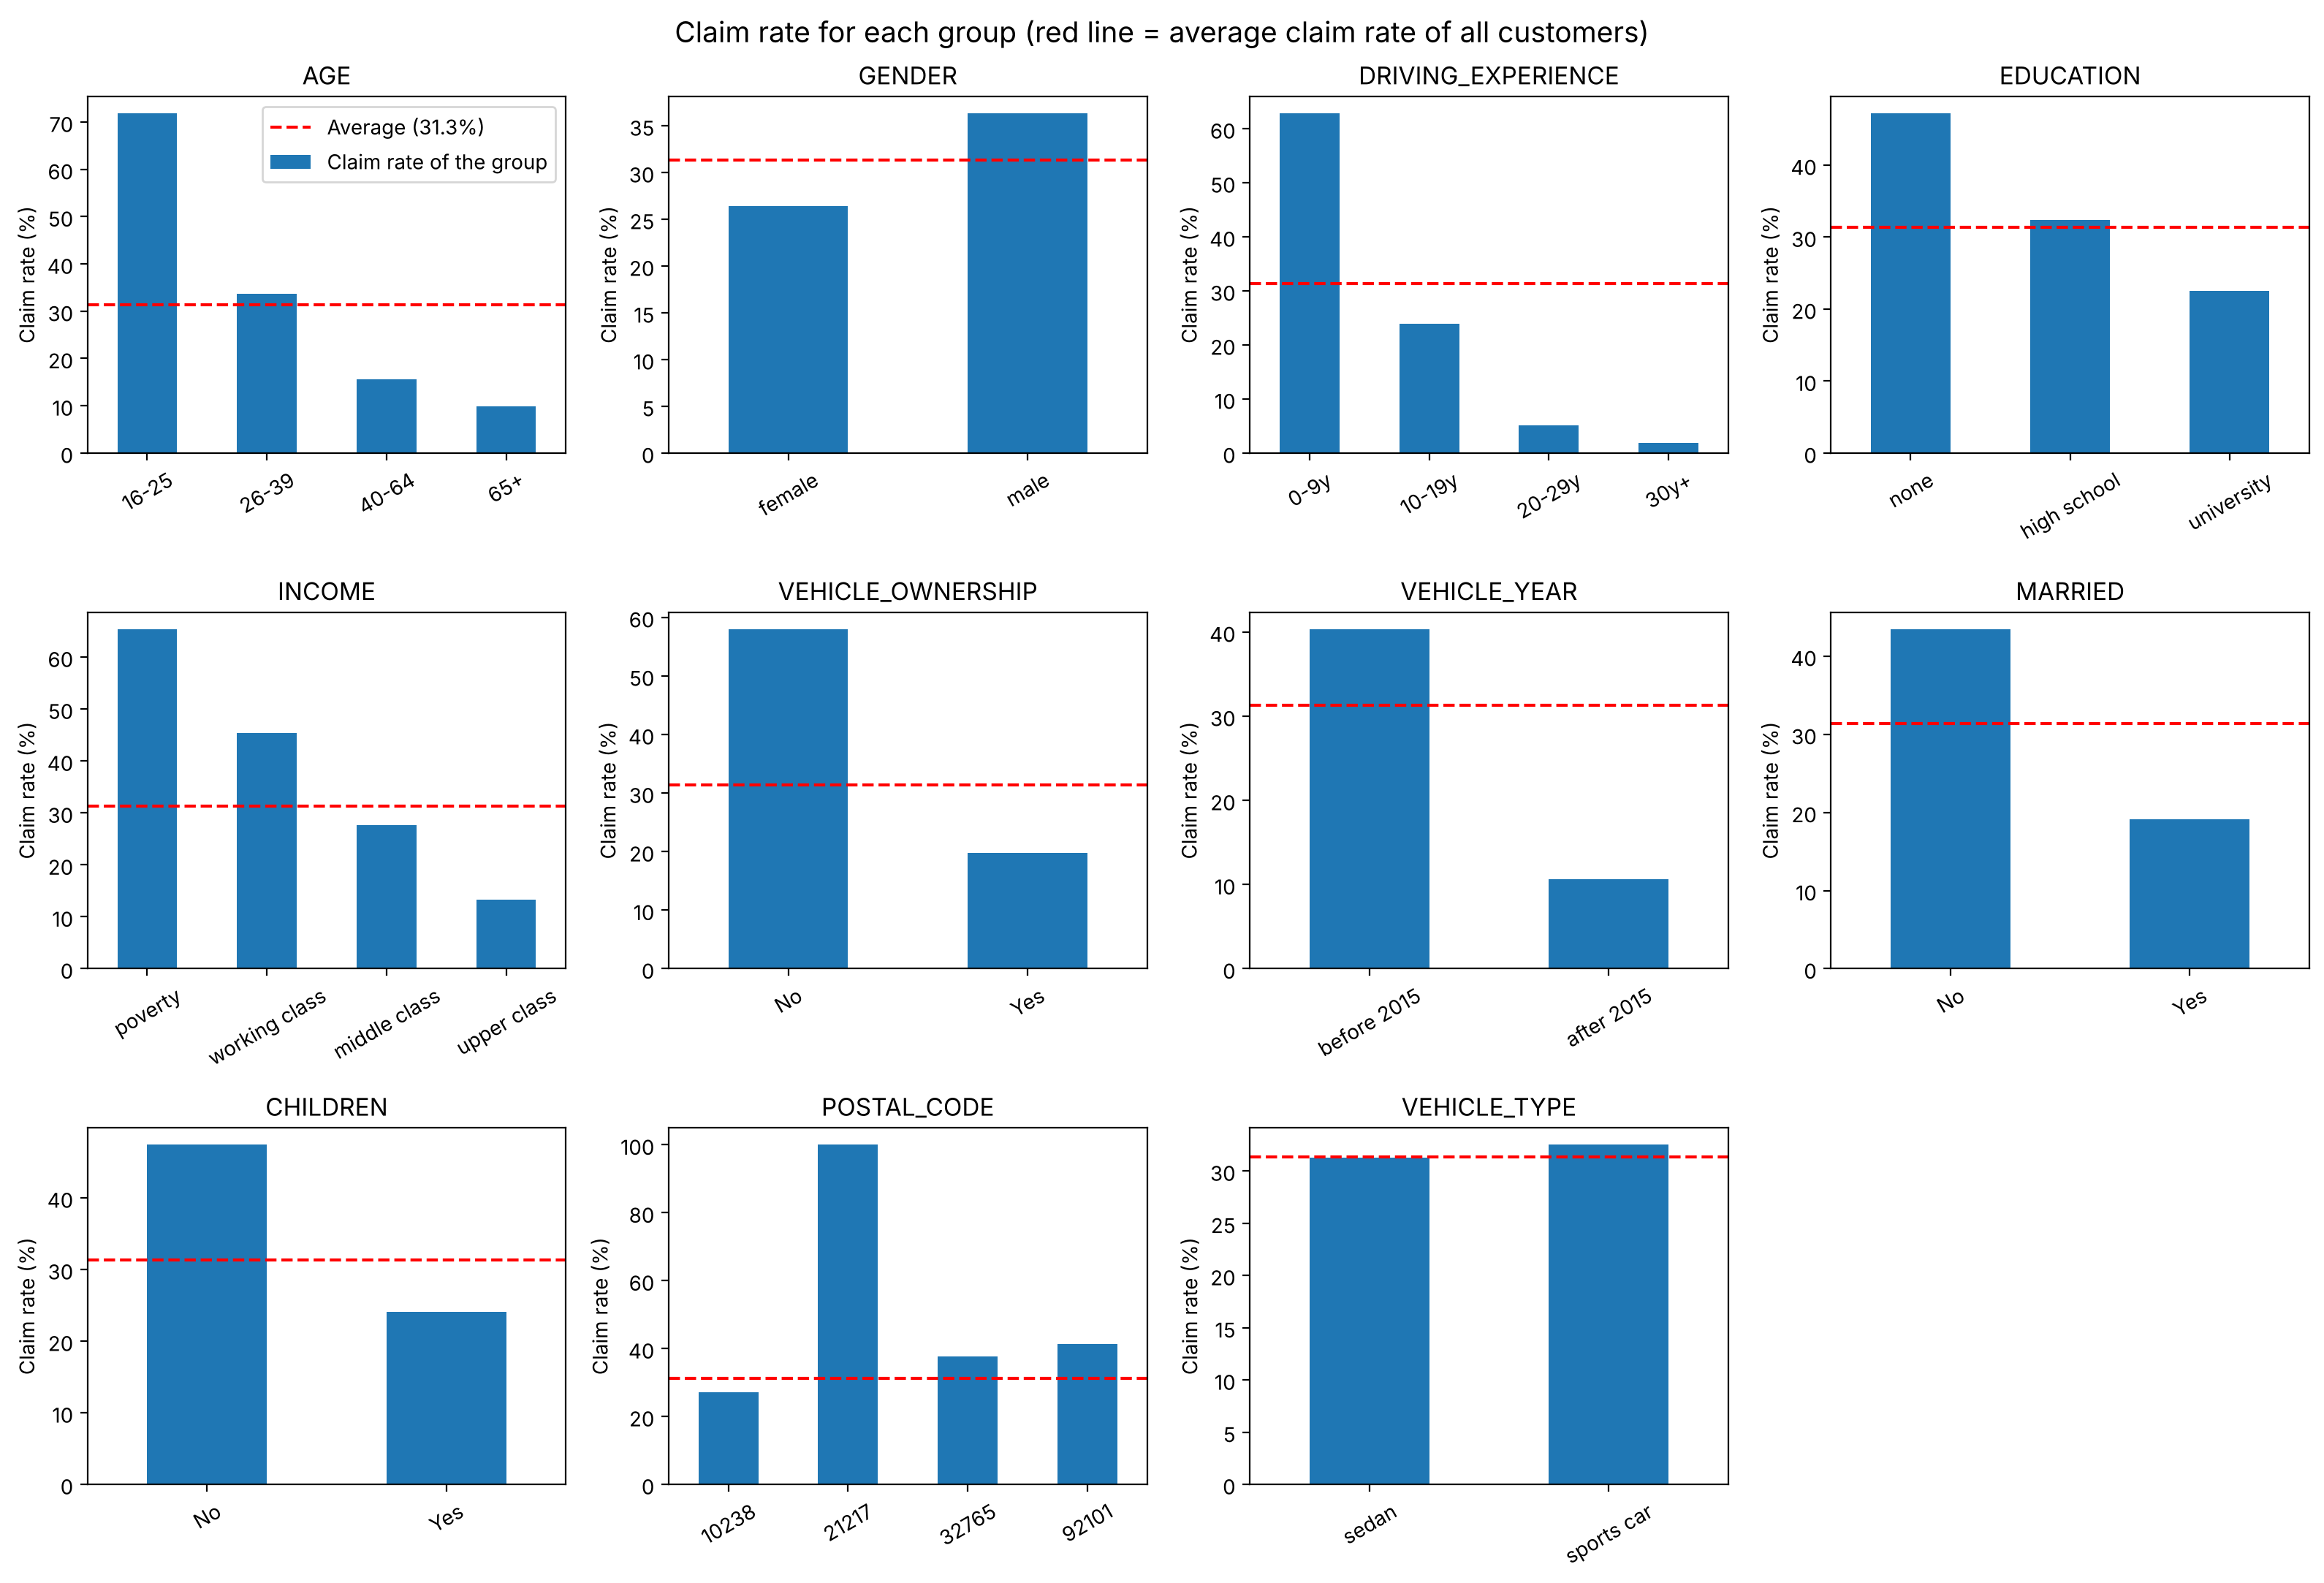

In [6]:
# The category columns I want to compare against OUTCOME
category_columns = ["AGE", "GENDER", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME",
                    "VEHICLE_OWNERSHIP", "VEHICLE_YEAR", "MARRIED", "CHILDREN",
                    "POSTAL_CODE", "VEHICLE_TYPE"]

overall_rate = df["OUTCOME"].mean() * 100

# Make a grid of 3 rows x 4 columns = 12 empty charts
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i in range(len(category_columns)):
    column = category_columns[i]
    chart = axes[i]

    claim_rate = df.groupby(column)["OUTCOME"].mean() * 100

    # Put the groups in a sensible order
    if column == "EDUCATION":
        claim_rate = claim_rate[["none", "high school", "university"]]
    if column == "INCOME":
        claim_rate = claim_rate[["poverty", "working class", "middle class", "upper class"]]
    if column == "VEHICLE_YEAR":
        claim_rate = claim_rate[["before 2015", "after 2015"]]
    # Show 0/1 columns as No/Yes so the chart is easy to read
    if column in ["VEHICLE_OWNERSHIP", "MARRIED", "CHILDREN"]:
        claim_rate = claim_rate.rename(index={0.0: "No", 1.0: "Yes"})

    claim_rate.name = "Claim rate of the group"
    claim_rate.plot(kind="bar", ax=chart, rot=30)
    chart.axhline(overall_rate, color="red", linestyle="--", label=f"Average ({overall_rate:.1f}%)")
    chart.set_title(column)
    chart.set_ylabel("Claim rate (%)")
    chart.set_xlabel("")

axes[0].legend()
axes[11].axis("off")
fig.suptitle("Claim rate for each group (red line = average claim rate of all customers)", fontsize=14)
plt.tight_layout()
plt.show()

**What these Show**
- **Age and driving experience** these seem to have the largest effect. 71.8% of 16-25 year olds claimed insurance compared to the 9.8% of 65+ year old drivers. Drivers with 0-9 years of experience claimed 62.8%, but those individuals with 30+ years only claimed 1.9%
- **GENDER:** Males claimed 36.3% and females 26.4%. Males are above the average and females are below it
- **VEHICLE_OWNERSHIP:** Customers Who Own their Car only claimed 19.7% of the time Compared to non Owners who claimed significantly more at 58.0%
- **EDUCATION :** No education claimed 47.2%, high school 32.3% and university 22.6%. The higher the education, the fewer the claims
- **INCOME** : The lower the income, the higher the claim rate: Poverty 65.4%, Working class 45.3%, Middle class 27.7%, Upper class 13.4%
- **MARRIED** : Not married customers claimed more than married customers. Not married: 43.4% -- Married: 19.1%
- **CHILDREN** : Customers with no children claimed more than customers with children. No children: 47.4% -- With children: 24.1%
- **VEHICLE_YEAR:** Cars made before 2015 claimed 40.3% compared to 10.6% for cars made after 2015.
- **VEHICLE_TYPE:** Sedan 31.3% and sports car 32.5%. Both are right on the average line, so vehicle type shows almost no link with claims.

**Overall Explanation :** Age,driving experience and income show the biggest differences as compared to the mean of claims . Many of these columns are linked to each other , example younger drivers have less experience and may also have lower income , most don't own their car and are not married.
So I can't say which of these columns actually causes claims. These are only patterns in the data.



### Question 2 : Do males still claim more than females if they have the same driving experience?
In Question 1 Males seemed to claim more than females. I want to check if the gap stays or disappears when drivers have the same driving experience. If it disappears, gender may not add anything once experience is known.



GENDER,female,male
DRIVING_EXPERIENCE,,
0-9y,54.4,71.5
10-19y,18.0,29.6
20-29y,3.7,6.6
30y+,2.1,1.7


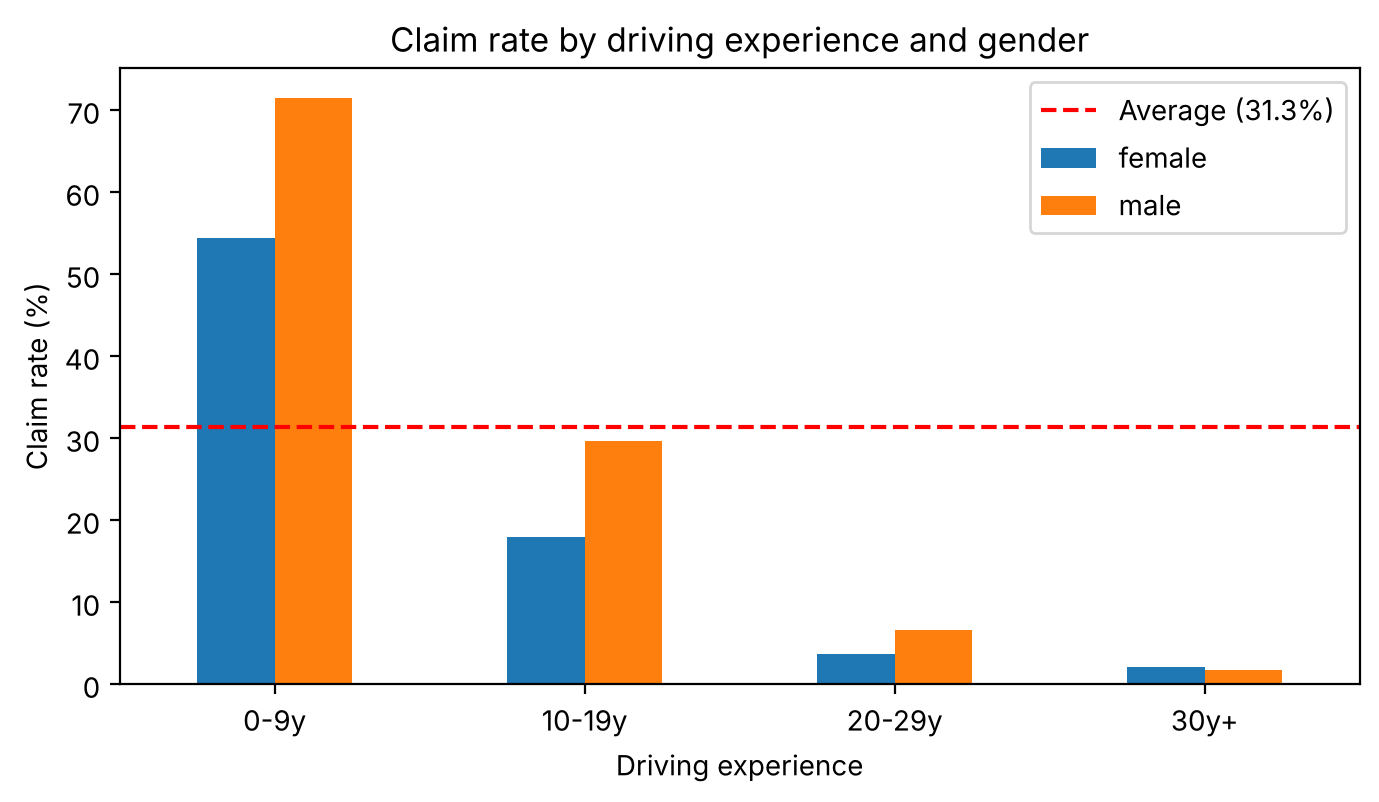

In [7]:
gender_table = pd.crosstab(index=df["DRIVING_EXPERIENCE"],
                           columns=df["GENDER"],
                           values=df["OUTCOME"],
                           aggfunc="mean") * 100
display(gender_table.round(1))


gender_table.plot(kind="bar", figsize=(8, 4), rot=0)
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Average ({overall_rate:.1f}%)")
plt.xlabel("Driving experience")
plt.ylabel("Claim rate (%)")
plt.legend()
plt.title("Claim rate by driving experience and gender")
plt.show()


**What these Show** 

|Experience|Female|Male|
|---|---|---|
|0-9y|54.4% | 71.5%| 
|10-19y|18.0% |29.6%| 
|20-29y| 3.7% | 6.6%| 
|30y+| 2.1% |1.7%| 

The gap between males and females stays when experience is the same, except for 30y+, where both are very low. The biggest gap is with new drivers (0-9y): 71.5% (M) vs 54.4% (F).
 This could possibly mean that the gender matters when predicting who will claim based on these results , the model could charge men more for the same driving record, which is a fairness problem. I will check whether the model treats males and females differently


### Question 3 : How are the values spread out in CREDIT_SCORE, ANNUAL_MILEAGE, SPEEDING_VIOLATIONS, DUIS and PAST_ACCIDENTS?
**Why I'm asking this:** I need to know the typical value, the spread and shape of each of these columns. This decides how I will fill missing values in Data Preparation, and will show any extreme values I need to check

Skew shows me  if a column is even (close to 0) or lopsided (above 1). Lopsided means most customers have low values but a few have very high ones. In a lopsided column the average gets pulled up by those few high values, so the middle value (median) is a better choice for filling in missing values.


,CREDIT_SCORE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS
count,9018.00,9043.00,10000.00,10000.00,10000.00
mean,0.52,11697.00,1.48,0.24,1.06
std,0.14,2818.43,2.24,0.55,1.65
min,0.05,2000.00,0.00,0.00,0.00
25%,0.42,10000.00,0.00,0.00,0.00
50%,0.53,12000.00,0.00,0.00,0.00
75%,0.62,14000.00,2.00,0.00,2.00
max,0.96,22000.00,22.00,6.00,15.00


CREDIT_SCORE          -0.23
ANNUAL_MILEAGE         0.04
SPEEDING_VIOLATIONS    2.37
DUIS                   2.76
PAST_ACCIDENTS         2.15
dtype: float64

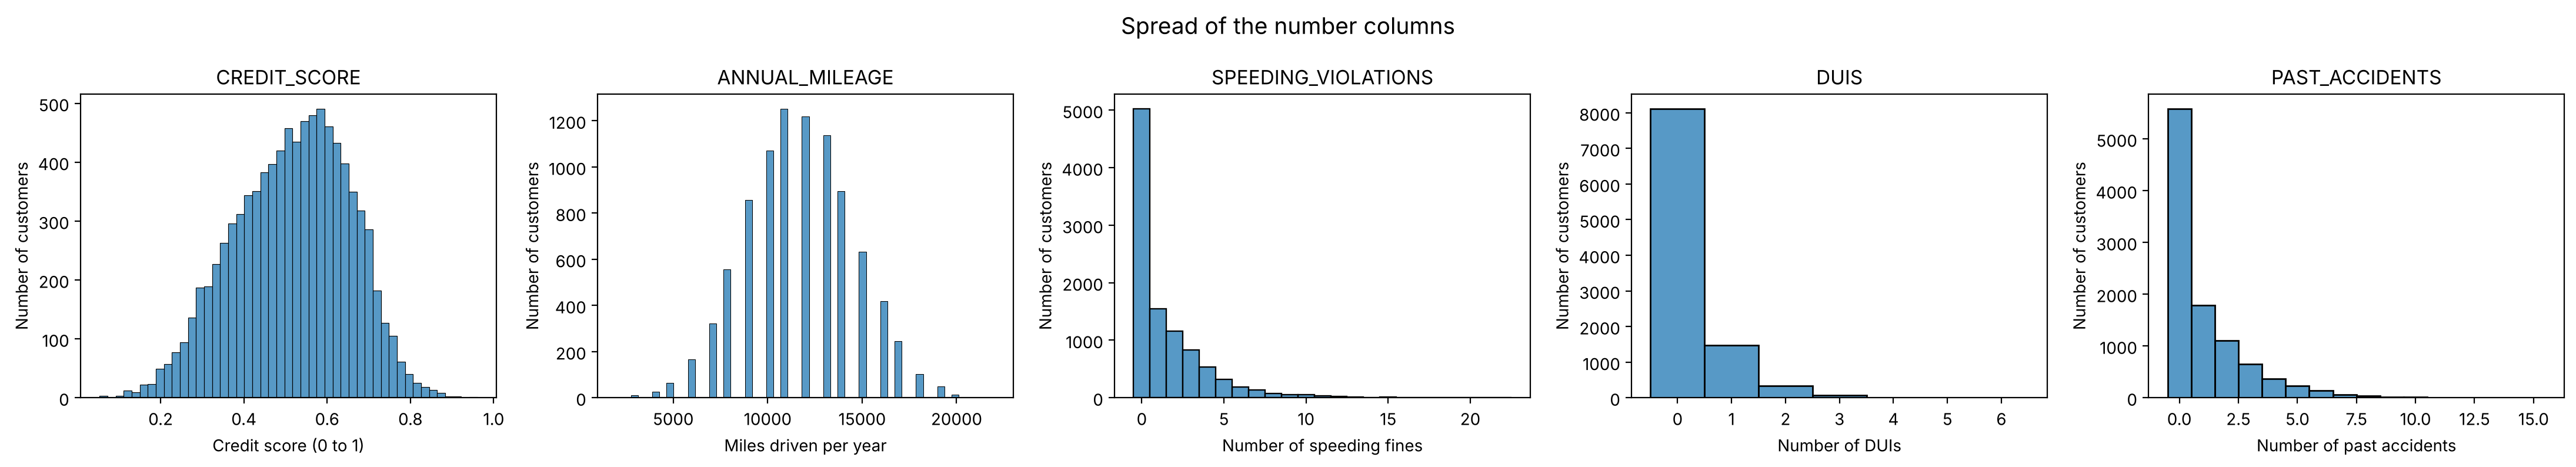

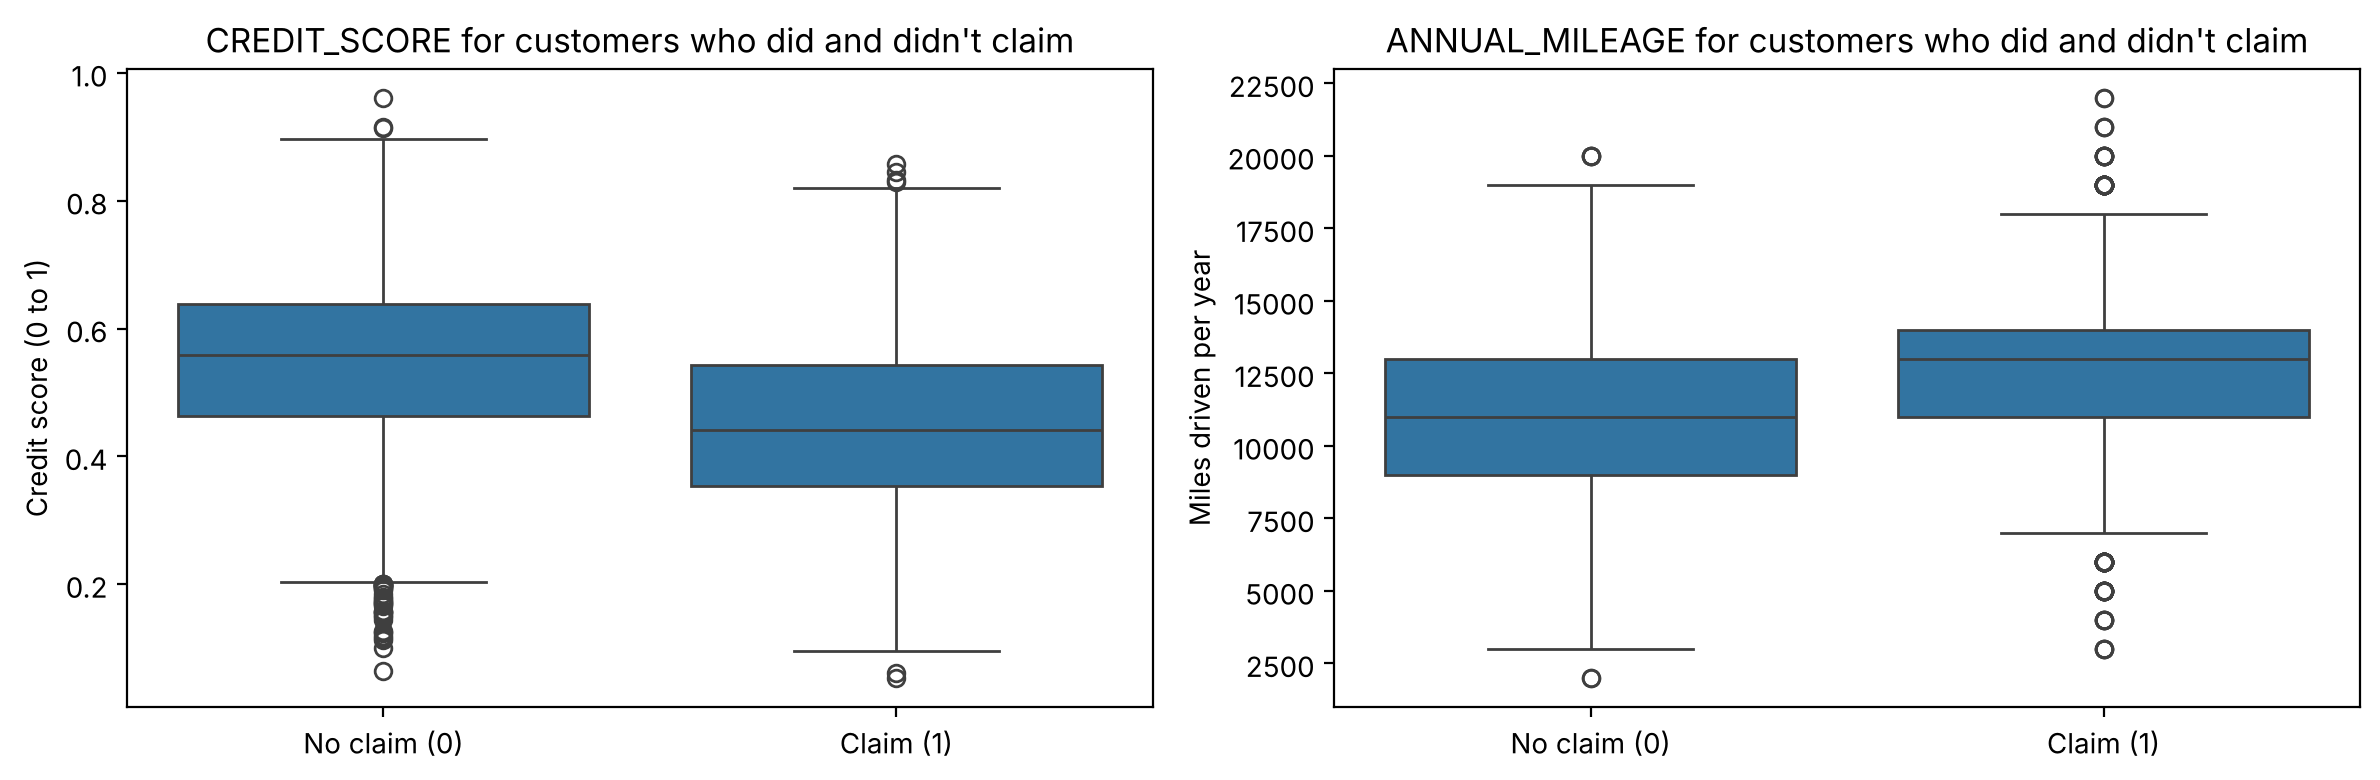

,CREDIT_SCORE,ANNUAL_MILEAGE
OUTCOME,,
0.0,0.559124,11000.0
1.0,0.440936,13000.0


In [8]:
# The 5 columns that hold numbers
number_columns = ["CREDIT_SCORE", "ANNUAL_MILEAGE", "SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]
axis_labels = {"CREDIT_SCORE": "Credit score (0 to 1)", "ANNUAL_MILEAGE": "Miles driven per year",
               "SPEEDING_VIOLATIONS": "Number of speeding fines", "DUIS": "Number of DUIs",
               "PAST_ACCIDENTS": "Number of past accidents"}

display(df[number_columns].describe().round(2))

# Skew for each column (0 = even, above 1 = lopsided)
display(df[number_columns].skew().round(2))

# Histograms (Lecture 2). Count columns get one bar per whole number (discrete=True)
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for i in range(len(number_columns)):
    column = number_columns[i]
    if column in ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]:
        sns.histplot(df[column], discrete=True, ax=axes[i])
    else:
        sns.histplot(df[column], ax=axes[i])
    axes[i].set_title(column)
    axes[i].set_xlabel(axis_labels[column])
    axes[i].set_ylabel("Number of customers")
fig.suptitle("Spread of the number columns", fontsize=14)
plt.tight_layout()
plt.show()

# Box plots split by OUTCOME (Lecture 2: compare a number column across groups)
# Only the two continuous columns - for the count columns most values are 0, so the box is flat
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i in range(2):
    column = number_columns[i]
    sns.boxplot(x="OUTCOME", y=column, data=df, ax=axes[i])
    axes[i].set_xticks([0, 1], ["No claim (0)", "Claim (1)"])
    axes[i].set_xlabel("")
    axes[i].set_ylabel(axis_labels[column])
    axes[i].set_title(column + " for customers who did and didn't claim")
plt.tight_layout()
plt.show()

# Median of each column for customers who did and didn't claim
display(df.groupby("OUTCOME")[["CREDIT_SCORE", "ANNUAL_MILEAGE"]].median())

**What this shows:**
- `CREDIT_SCORE` and `ANNUAL_MILEAGE` are balanced (skew -0.23 and 0.04). Most customers are around the middle, and the mean and median are almost the same (0.52 vs 0.53, and 11,697 vs 12,000 miles).
- `SPEEDING_VIOLATIONS`, `DUIS` and `PAST_ACCIDENTS` are lopsided (skew above 2). Most customers have 0, but a few have a lot: up to 22 speeding violations, 6 DUIs and 15 accidents.


- What I learned performing these tasks is that the mean can be misleading when a column is lopsided. 'SPEEDING_VIOLATIONS' has a mean of 1.48 but a median of 0, so the typical customer has no violations. A few customers with very high values pull the average up

- The two columns with missing values (`CREDIT_SCORE` and `ANNUAL_MILEAGE`) are both even, so the mean and median are almost the same. I will use the median to fill the gaps, as it is safe either way.
- I will check the very high values in `SPEEDING_VIOLATIONS`, `DUIS` and `PAST_ACCIDENTS` as possible outliers in the Data Quality Report.

- **Box plots:** customers who claimed have a lower credit score (median 0.44 vs 0.56) and drive more (median 13,000 vs 11,000 miles). The boxes overlap a lot, so neither column splits claimers from non-claimers on its own. I did not split the count columns this way because most of their values are 0, so the boxes would be flat. They get their own box plots in 2.4.

### Question 4 : Do drivers with past accidents seem to claim more ? 

I would expect drivers who have had accidents before to be more likely to claim again. I want to check if the data shows this, because PAST_ACCIDENTS could be a useful input for the model.



PAST_ACCIDENTS
0    47.0
1    15.0
2    13.0
3     8.5
4     7.4
5     3.3
Name: Claim rate of the group, dtype: float64

PAST_ACCIDENTS
0    5584
1    1783
2    1104
3     646
4     366
5     517
Name: count, dtype: int64

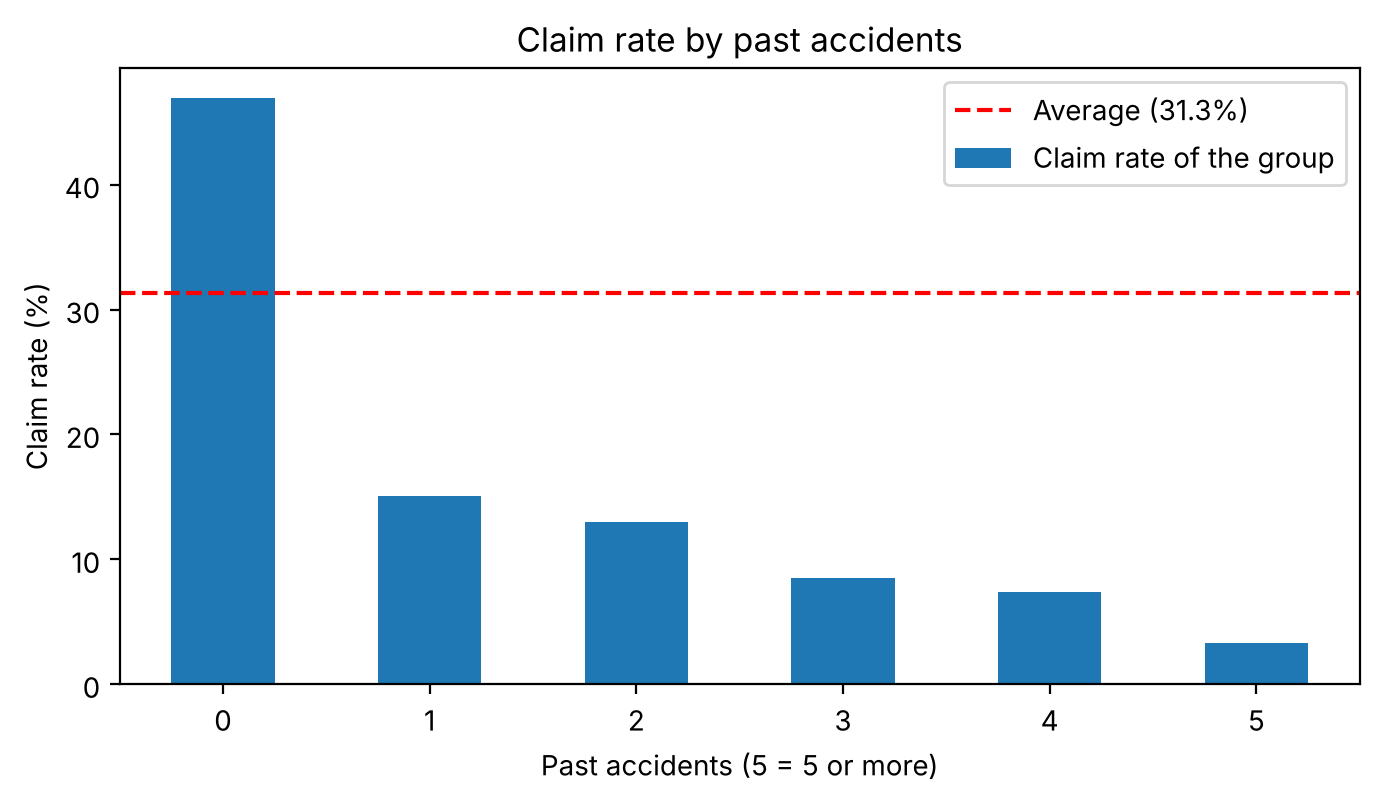

In [9]:

overall_rate = df["OUTCOME"].mean() * 100   
accidents = df["PAST_ACCIDENTS"].clip(upper=5)


accident_rate = df.groupby(accidents)["OUTCOME"].mean() * 100
accident_rate.name = "Claim rate of the group"
display(accident_rate.round(1))

# How many customers in each group
display(accidents.value_counts().sort_index())

accident_rate.plot(kind="bar", figsize=(8, 4), rot=0)
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Average ({overall_rate:.1f}%)")
plt.legend()
plt.ylabel("Claim rate (%)")
plt.xlabel("Past accidents (5 = 5 or more)")
plt.title("Claim rate by past accidents")
plt.show()

**What these results Show**
Drivers with 0 past accidents claimed 47.0%, well above the average of 31.3% (red line).
The claim rate based on this graph seems to go down as past accidents go up 

This is completely the opposite of what I expected because drivers who have been in past accidents generally are seen as higher risk 
A possible reason could be the driving experience . All drivers aged 16-25 have 0 past accidents because they have not been driving long and this group shows to have claimed the most (71.8%)

I can't really say that past accidents make people likely to claim. This is a link in the data but not a cause.
In Question 5 I compare drivers with the same driving experience to check this.


### Question 5 : Do drivers with past accidents claim more than drivers with the same experience who have none?


,No past accidents,Has past accidents
DRIVING_EXPERIENCE,,
0-9y,62.8,NaN
10-19y,26.0,22.2
20-29y,5.8,5.0
30y+,4.3,1.5


PAST_ACCIDENTS,False,True
DRIVING_EXPERIENCE,,
0-9y,3530,0
10-19y,1431,1868
20-29y,485,1634
30y+,138,914


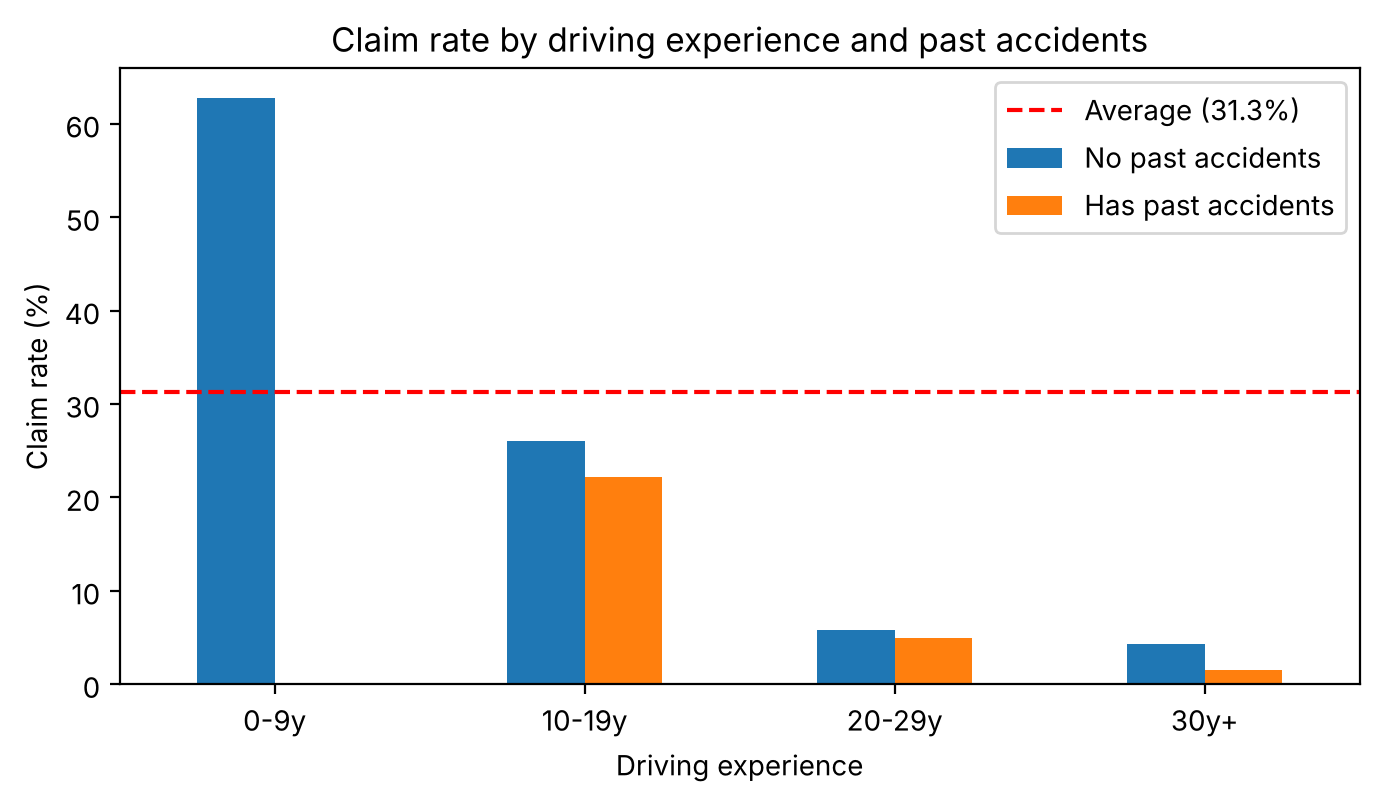

In [10]:

has_accident = df["PAST_ACCIDENTS"] > 0


accident_table = pd.crosstab(df["DRIVING_EXPERIENCE"], has_accident,
                             values=df["OUTCOME"], aggfunc="mean") * 100
accident_table.columns = ["No past accidents", "Has past accidents"]
display(accident_table.round(1))


display(pd.crosstab(df["DRIVING_EXPERIENCE"], has_accident))

accident_table.plot(kind="bar", figsize=(8, 4), rot=0)
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Average ({overall_rate:.1f}%)")
plt.xlabel("Driving experience")
plt.ylabel("Claim rate (%)")
plt.legend()
plt.title("Claim rate by driving experience and past accidents")
plt.show()

**What these Show**
- New drivers (0-9y) all have 0 past accidents, so they can't be compared (no orange bar)
- In the other groups, drivers with accidents don't claim more. They actually claim a bit less: 10-19y 22.2% vs 26.0%, 20-29y 5.0% vs 5.8%, 30y+ 1.5% vs 4.3%.
- Experience makes a much bigger difference than accidents: the claim rate drops from 62.8% for 0-9y to 5.1% for 20-29y and 1.9% for 30y+.


So the Question 4 pattern was mostly because of new drivers, who all have 0 accidents and claim the most.
It is strange that no new driver has had an accident, so I will note this in the Data Quality Report.

Because of this, I will not use `PAST_ACCIDENTS` in the model. Even with the same experience, drivers with accidents claim less in this data, so a model would give lower risk to drivers with more accidents. I remove it in Data Preparation and record it in the preparation log.



### Question 6 : How are the number columns linked to each other and to OUTCOME?
**Why I'm asking this:** Q1 to Q5 looked at one or two columns at a time. A correlation matrix (as in Lab 1) shows all the number columns together, so I can see which ones are most linked to claims and which ones are linked to each other. A correlation only shows a link, not a cause.

VEHICLE_OWNERSHIP     -0.38
CREDIT_SCORE          -0.33
PAST_ACCIDENTS        -0.31
SPEEDING_VIOLATIONS   -0.29
MARRIED               -0.26
CHILDREN              -0.23
DUIS                  -0.19
ANNUAL_MILEAGE         0.19
OUTCOME                1.00
Name: OUTCOME, dtype: float64

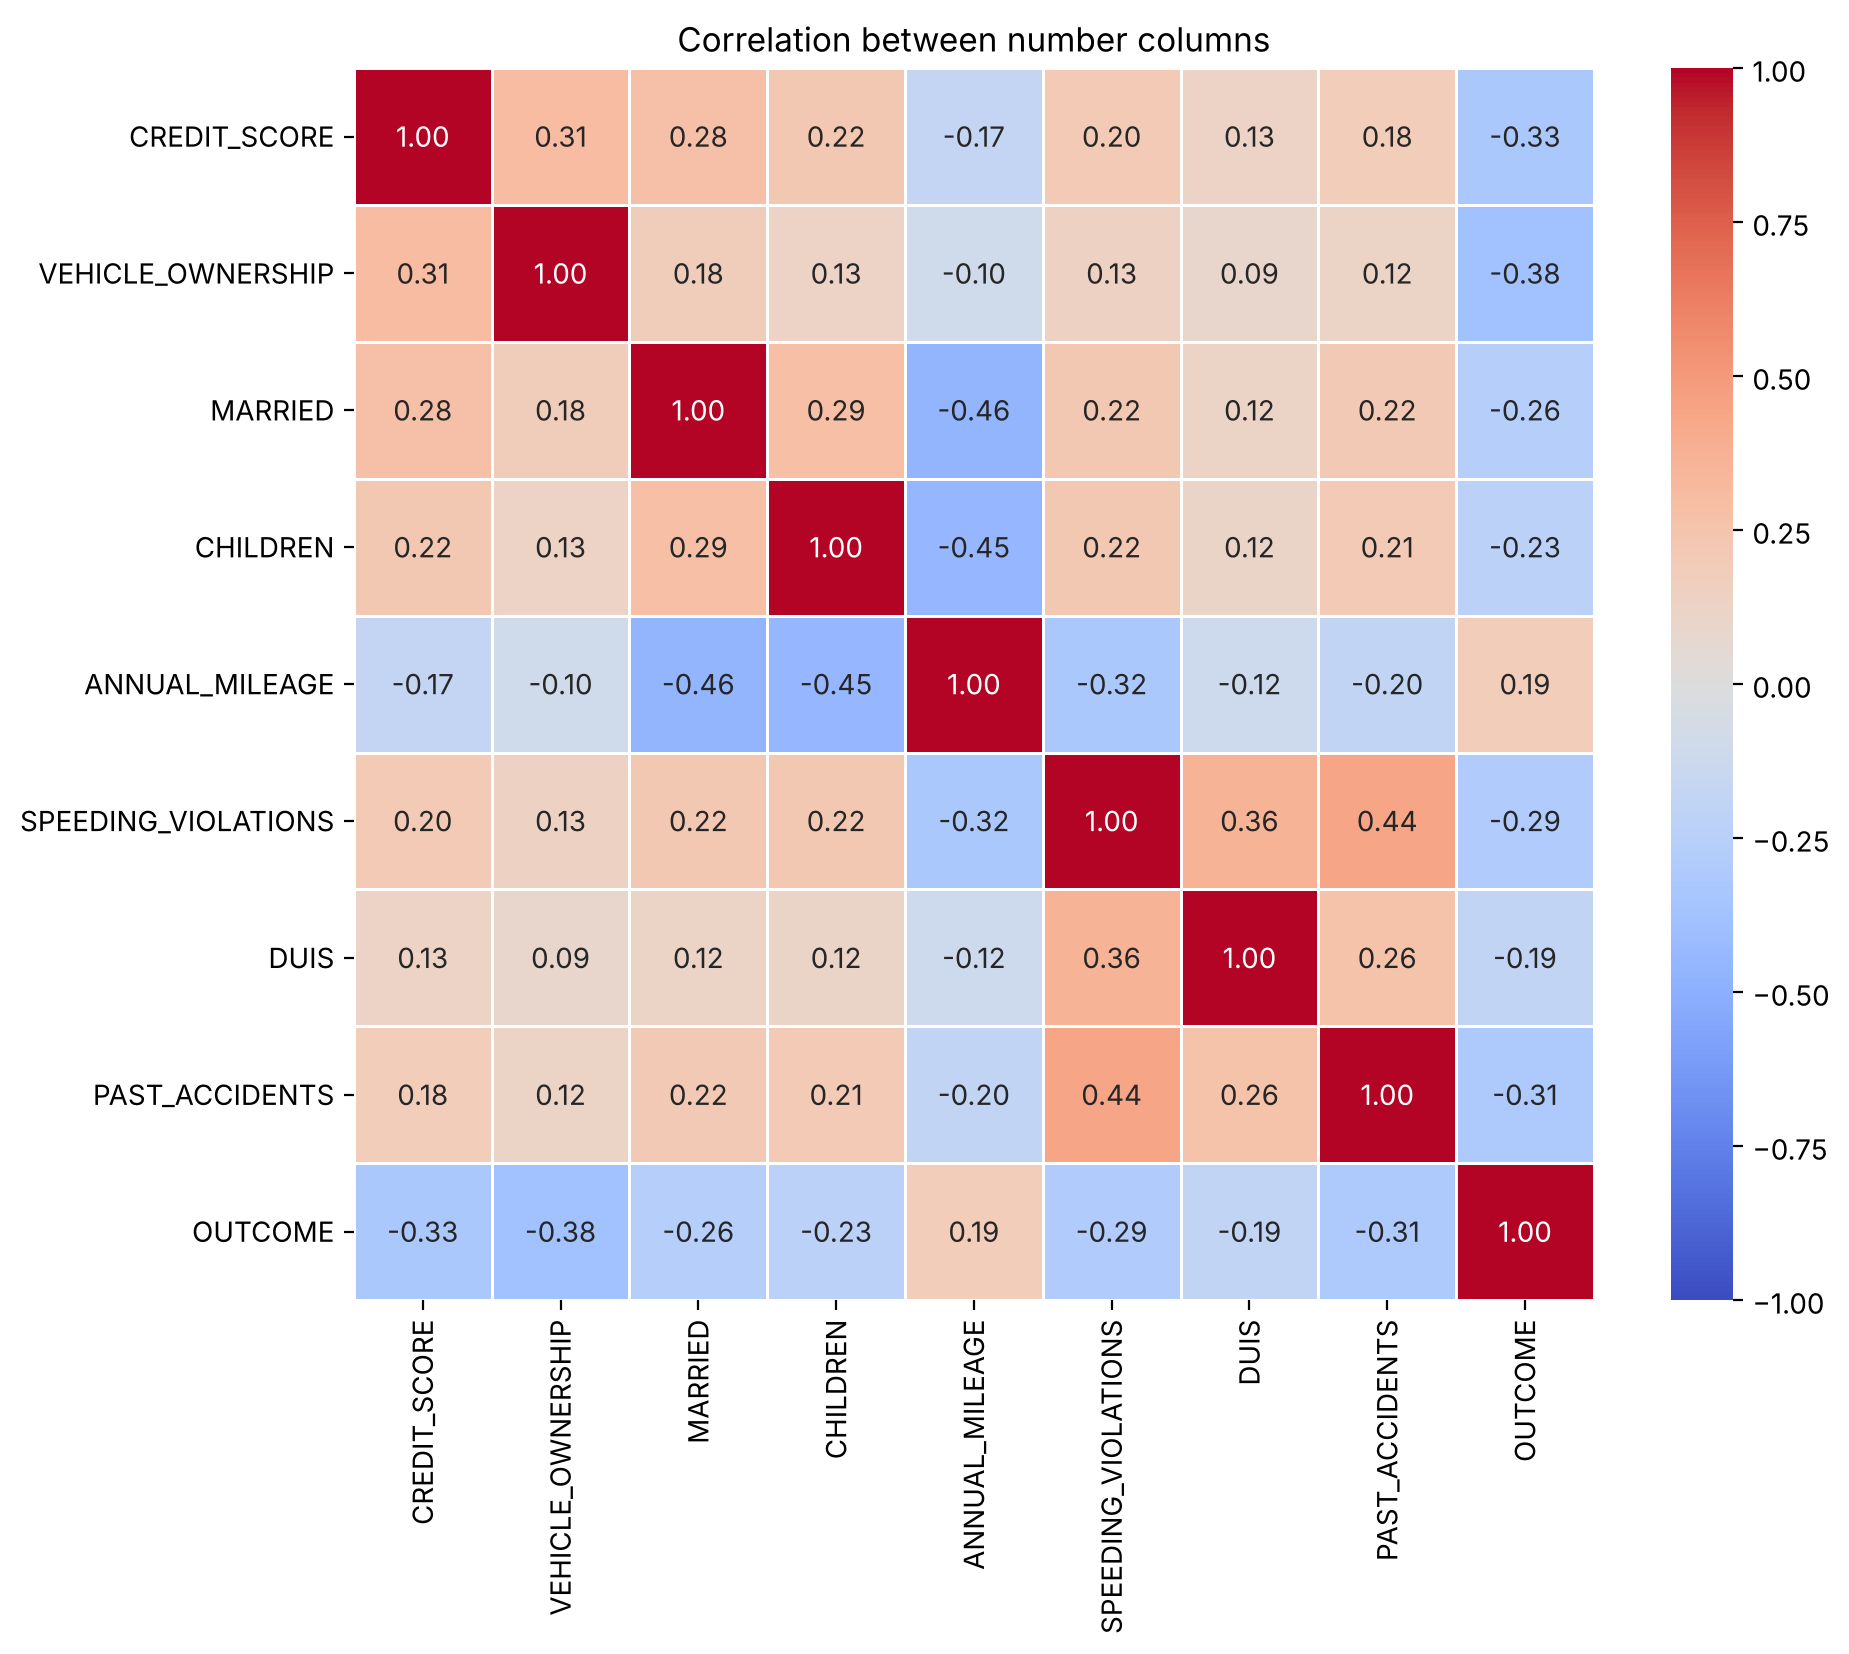

In [11]:
# Number columns only (ID and POSTAL_CODE left out because they are labels, not amounts)
corr_columns = ["CREDIT_SCORE", "VEHICLE_OWNERSHIP", "MARRIED", "CHILDREN", "ANNUAL_MILEAGE",
                "SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS", "OUTCOME"]
correlation_matrix = df[corr_columns].corr()

# Correlation of each column with OUTCOME, most negative first (as in Lab 1)
display(correlation_matrix["OUTCOME"].sort_values().round(2))

# Heatmap of the whole matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", linewidths=1, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between number columns")
plt.show()

**What these Show**
- The columns most linked to OUTCOME are VEHICLE_OWNERSHIP (-0.38), CREDIT_SCORE (-0.33) and PAST_ACCIDENTS (-0.31). Negative means customers with a higher value claim less. ANNUAL_MILEAGE is the only positive one (0.19): people who drive more claim more.
- SPEEDING_VIOLATIONS (-0.29) and DUIS (-0.19) are also negative, which looks backwards. This is the same pattern as PAST_ACCIDENTS in Q4: new drivers have zero offences but claim the most. In Q5 I checked within the same experience group and these two did not show the backwards pattern, so I keep them.
- The strongest links between two inputs are MARRIED and ANNUAL_MILEAGE (-0.46), CHILDREN and ANNUAL_MILEAGE (-0.45) and SPEEDING_VIOLATIONS and PAST_ACCIDENTS (0.44). These are moderate, so no input is a copy of another and I keep them all.
- These are only straight-line links between number columns. The text columns (AGE, DRIVING_EXPERIENCE, INCOME) are not in the matrix, but Q1 already showed they have the biggest differences.

## 2.4 Data Quality Report

### Missing values
**Reason for checking this:** In 1.6 I assumed that CREDIT_SCORE and ANNUAL_MILEAGE are missing at random.
I need to check this before filling them, because if the gaps belong to a certain type of customer, filling them could potentially add bias


ID                       0
AGE                      0
GENDER                   0
RACE                     0
DRIVING_EXPERIENCE       0
EDUCATION                0
INCOME                   0
CREDIT_SCORE           982
VEHICLE_OWNERSHIP        0
VEHICLE_YEAR             0
MARRIED                  0
CHILDREN                 0
POSTAL_CODE              0
ANNUAL_MILEAGE         957
VEHICLE_TYPE             0
SPEEDING_VIOLATIONS      0
DUIS                     0
PAST_ACCIDENTS           0
OUTCOME                  0
dtype: int64
ID                     0.0
AGE                    0.0
GENDER                 0.0
RACE                   0.0
DRIVING_EXPERIENCE     0.0
EDUCATION              0.0
INCOME                 0.0
CREDIT_SCORE           9.8
VEHICLE_OWNERSHIP      0.0
VEHICLE_YEAR           0.0
MARRIED                0.0
CHILDREN               0.0
POSTAL_CODE            0.0
ANNUAL_MILEAGE         9.6
VEHICLE_TYPE           0.0
SPEEDING_VIOLATIONS    0.0
DUIS                   0.0
PAST_ACCIDENTS 

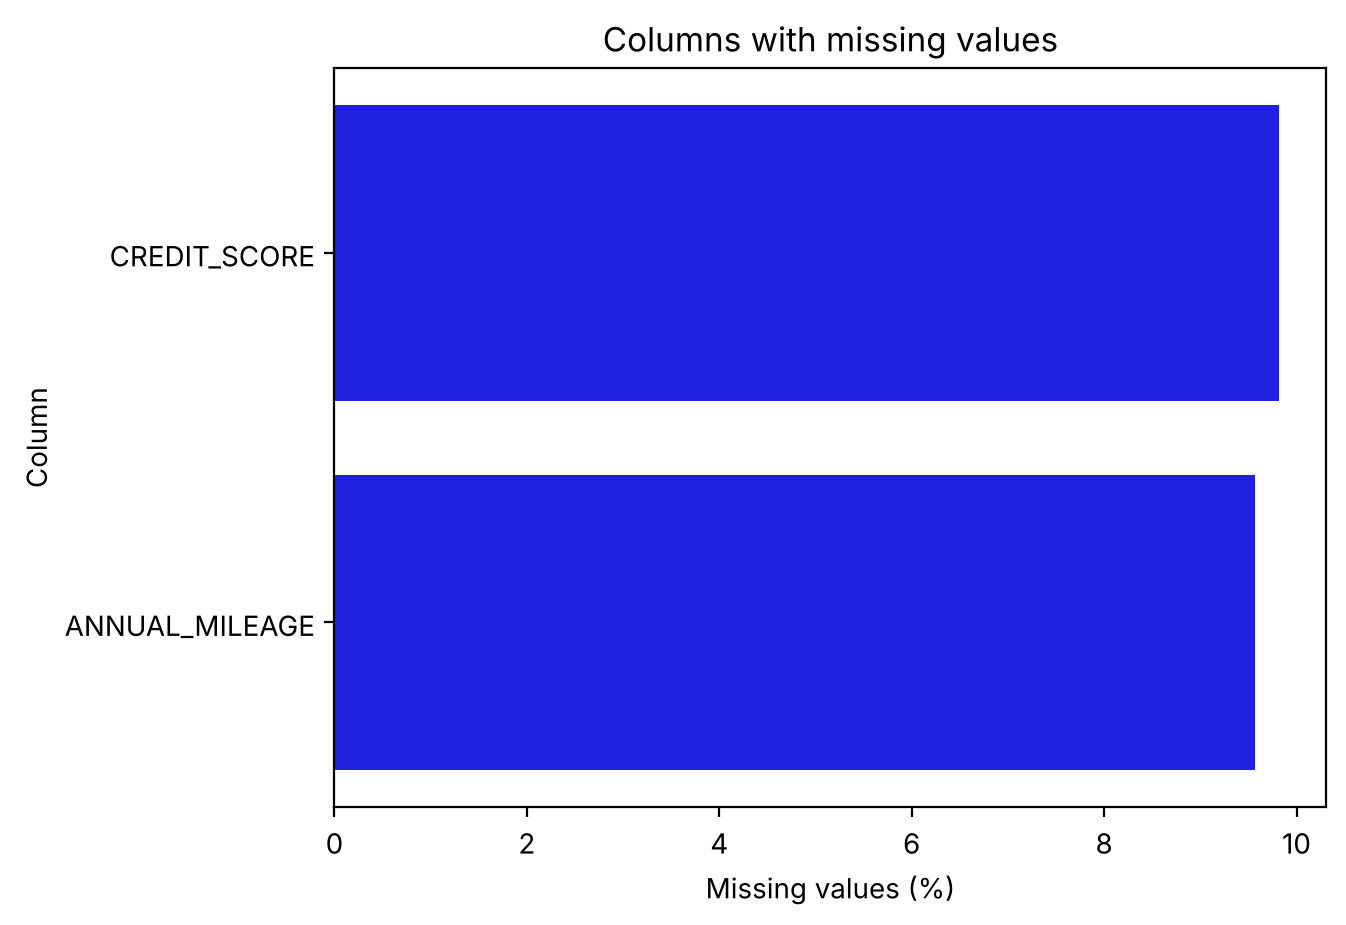

In [12]:
# How many values are missing in each column
missing = df.isnull().sum()
print(missing)

# The same thing as a percentage
missing_percent = df.isnull().mean() * 100
print(missing_percent.round(1))

# How many customers are missing both columns
missing_both = df["CREDIT_SCORE"].isnull() & df["ANNUAL_MILEAGE"].isnull()
print("Missing both:", missing_both.sum())

# Claim rate for customers with a credit score (False) and without one (True)
credit_missing = df["CREDIT_SCORE"].isnull()
print((df.groupby(credit_missing)["OUTCOME"].mean() * 100).round(1))

# Same check for mileage
mileage_missing = df["ANNUAL_MILEAGE"].isnull()
print((df.groupby(mileage_missing)["OUTCOME"].mean() * 100).round(1))

# Bar chart of the % missing in each column (as in Lab 3)
missing_share = df.isnull().mean() * 100
missing_share = missing_share[missing_share > 0].sort_values(ascending=False)   # only columns with gaps
sns.barplot(x=missing_share.values, y=missing_share.index, color="b")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Columns with missing values")
plt.show()

**What these Show**

Only CREDIT_SCORE (9.8%) and ANNUAL_MILEAGE (9.6%) have gaps. 88 customers are missing both, which is about what you’d expect by chance (~94), so the gaps aren’t linked. Customers with gaps claim at nearly the same rate, so the assumption in 1.6 looks OK. I can’t be sure why they’re missing, as Kaggle doesn’t say. I’ll fill them with the median from the training data in Data Preparation.

### Duplicates, invalid values, categories and units

**Why I'm checking this:** Duplicate customers would be counted twice, and impossible values would
be errors to fix before modelling.

In [13]:
# Any rows that appear twice?
print("Duplicate rows:", df.duplicated().sum())

# Any customer ID used twice?
print("Duplicate IDs:", df["ID"].duplicated().sum())

# These columns should only hold 0 or 1
print("VEHICLE_OWNERSHIP:", df["VEHICLE_OWNERSHIP"].unique())
print("MARRIED:", df["MARRIED"].unique())
print("CHILDREN:", df["CHILDREN"].unique())
print("OUTCOME:", df["OUTCOME"].unique())

# Lowest value in each count column (should not be below 0)
print(df[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].min())

# Credit score should be between 0 and 1
print("Lowest credit score:", df["CREDIT_SCORE"].min().round(2))
print("Highest credit score:", df["CREDIT_SCORE"].max().round(2))

# Check no one has more years of driving experience than their age allows
print(pd.crosstab(df["AGE"], df["DRIVING_EXPERIENCE"]))

Duplicate rows: 0
Duplicate IDs: 0
VEHICLE_OWNERSHIP: [1. 0.]
MARRIED: [0. 1.]
CHILDREN: [1. 0.]
OUTCOME: [0. 1.]
SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
dtype: int64
Lowest credit score: 0.05
Highest credit score: 0.96
DRIVING_EXPERIENCE  0-9y  10-19y  20-29y  30y+
AGE                                           
16-25               2016       0       0     0
26-39                683    2380       0     0
40-64                533     587    1811     0
65+                  298     332     308  1052


**What these show**

No duplicates or impossible values were found, so nothing needs fixing here. The category spellings were already checked in 2.2 and are consistent. Two things I can’t check: ANNUAL_MILEAGE has no unit (I assume miles because the data is from the US) and the CREDIT_SCORE scale isn’t explained. The 0/1 columns are stored as decimals (0.0/1.0). I don't need to change them because a decision tree treats 0.0 and 0 the same

### Outliers and unusual values
**Why I'm checking this:** In Q3 the count columns had a few very high values. I need to decide if
they are mistakes or real customers. I also found two strange patterns earlier (postal codes in Q1
and new drivers in Q5) that I need to check.

SPEEDING_VIOLATIONS - limit: 5.0 - outliers: 588
DUIS - limit: 0.0 - outliers: 1882
PAST_ACCIDENTS - limit: 5.0 - outliers: 285


,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS
AGE,,,
16-25,0,0,0
26-39,10,3,7
40-64,17,5,9
65+,22,6,15


POSTAL_CODE
10238    6940
32765    2456
92101     484
21217     120
Name: count, dtype: int64

POSTAL_CODE
10238     27.2
21217    100.0
32765     37.7
92101     41.3
Name: OUTCOME, dtype: float64

SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
dtype: int64

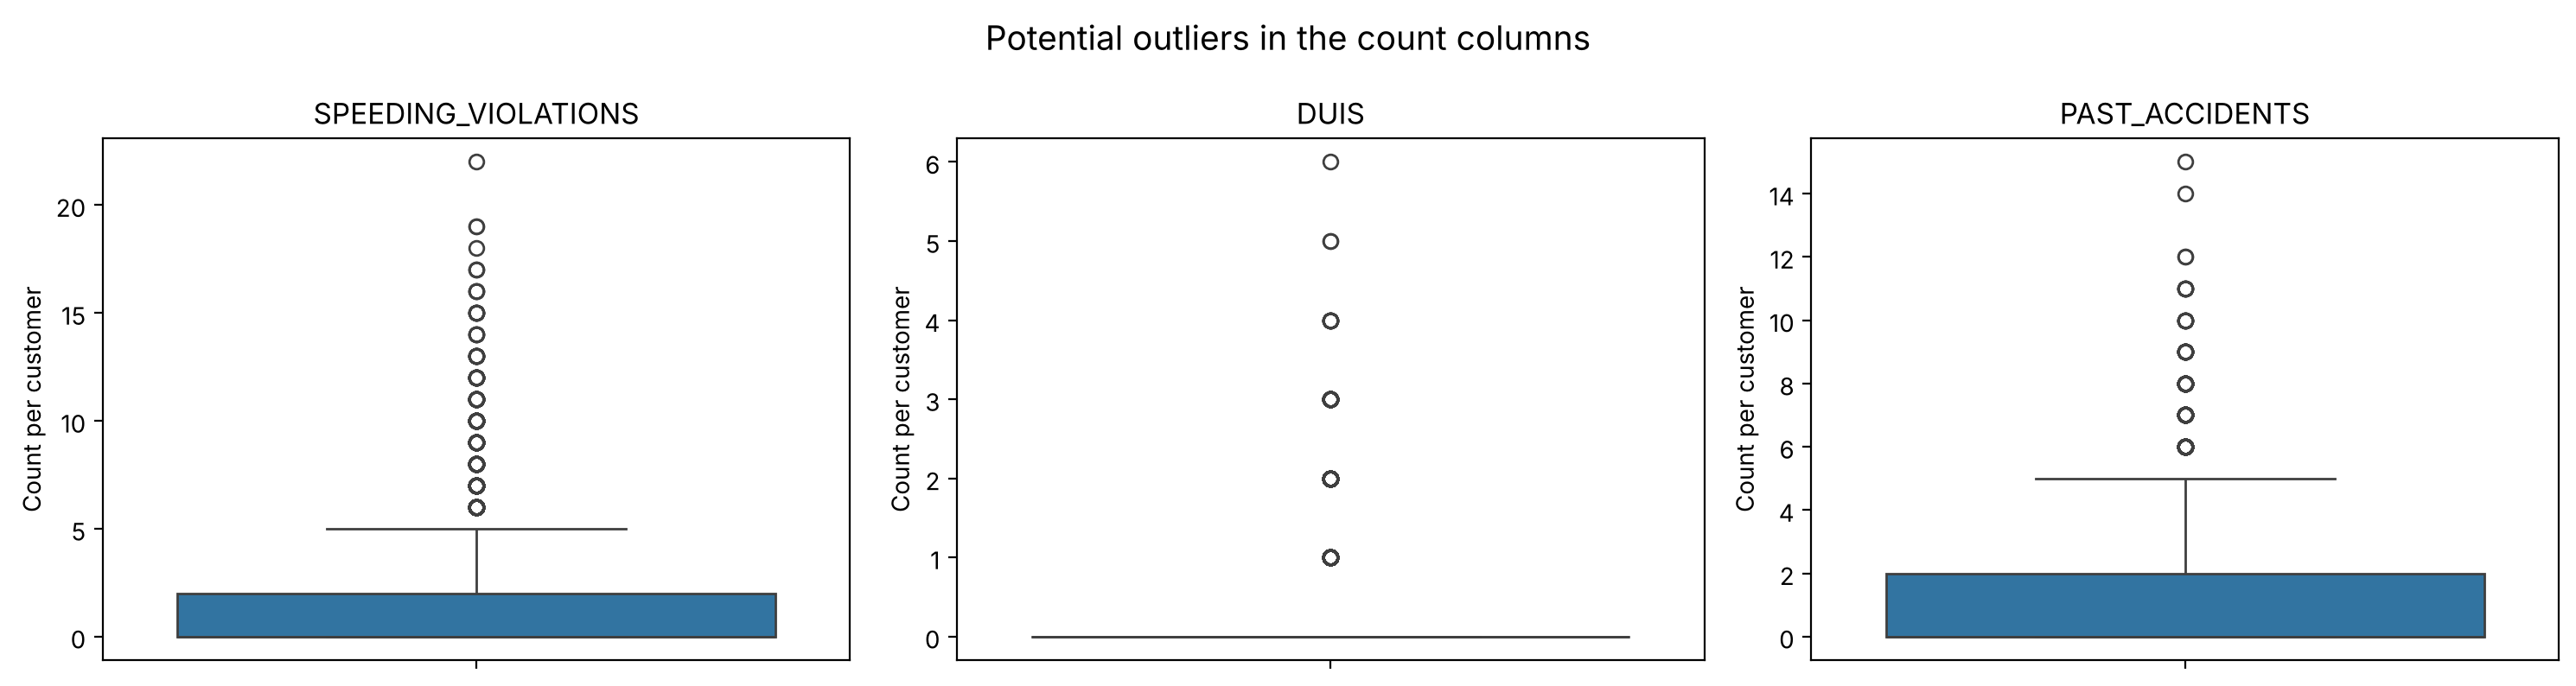

In [14]:


for column in ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]:
    q1 = df[column].quantile(0.25)          
    q3 = df[column].quantile(0.75)          
    upper_limit = q3 + 1.5 * (q3 - q1)      
    outliers = (df[column] > upper_limit).sum()
    print(column, "- limit:", upper_limit, "- outliers:", outliers)


# Highest value in each age group
display(df.groupby("AGE")[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].max())

# How many customers in each postal code, and their claim rate

display(df["POSTAL_CODE"].value_counts())
display((df.groupby("POSTAL_CODE")["OUTCOME"].mean() * 100).round(1))

# Only the 0-9y drivers, then their highest value - 0 means none of them have any

new_drivers = df[df["DRIVING_EXPERIENCE"] == "0-9y"]
display(new_drivers[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].max())

# Box plots of the count columns (Lecture 2): dots above the top whisker are potential outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
count_columns = ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]
for i in range(len(count_columns)):
    sns.boxplot(y=df[count_columns[i]], ax=axes[i])
    axes[i].set_title(count_columns[i])
    axes[i].set_ylabel("Count per customer")
fig.suptitle("Potential outliers in the count columns", fontsize=14)
plt.tight_layout()
plt.show()

**What these show**

- The IQR rule finds 588 speeding, 1,882 DUI and 285 accident outliers. For DUIS the limit is 0 because most people have none, so even 1 DUI counts as an outlier. The rule doesn't suit this kind of data. The box plots show the same thing: the DUIS box is flat at 0 and every DUI is drawn as a dot. The age table shows the highest counts belong to older drivers (up to 22 speeding fines for 65+), so they look like real drivers and I am keeping them

- Most customers are in postal code 10238 (6,940). 21217 is tiny, with only 120.
- Three areas have claim rates between 27% and 41%, which is normal next to the 31.3% average. But 21217 is 100%: every one of its 120 customers claimed. This is not realistic. A model would learn "if you live in 21217, you will claim", which is a fake rule.

- New drivers (0-9y) have zero speeding fines, zero DUIs and zero past accidents. It is all zero, but in real life at least some new drivers would have a fine or an accident. This suggests the data was partly generated. I can’t fix this, so I will list it as a limitation, as the model may not work the same on real insurance data.

### Representation, imbalance and bias
**Why I'm checking this:** Small groups give the model little to learn from, and the target
balance decides how I judge the model.

In [15]:
# % of customers in each group
for column in ["OUTCOME", "RACE", "GENDER", "VEHICLE_TYPE"]:
    display((df[column].value_counts(normalize=True) * 100).round(1))

# Claim rate for each race group
(df.groupby("RACE")["OUTCOME"].mean() * 100).round(1)

OUTCOME
0.0    68.7
1.0    31.3
Name: proportion, dtype: float64

RACE
majority    90.1
minority     9.9
Name: proportion, dtype: float64

GENDER
female    50.1
male      49.9
Name: proportion, dtype: float64

VEHICLE_TYPE
sedan         95.2
sports car     4.8
Name: proportion, dtype: float64

RACE
majority    31.2
minority    32.5
Name: OUTCOME, dtype: float64

**What these Show**

- Imbalance: only 31.3% claimed, so a model that always says “no claim” is 68.7% right.

- Small groups: sports cars are only 4.8%, so results for them are less reliable.

- Bias: both race groups claim about the same (31.2 vs 32.5), so dropping RACE loses little. Males claim more (Q2), so check the model is fair to both genders.
- Limitations: US only, no dates, licence unknown, data looks partly generated.

### Prioritised issues for Data Preparation

| Priority | Issue | Action |
|---|---|---|
| 1 | Postal code 21217 has 100% claims | Drop POSTAL_CODE |
| 2 | Target imbalanced (31.3% claims) | Stratified split, use recall/F1 |
| 3 | ~10% missing in CREDIT_SCORE and ANNUAL_MILEAGE | Fill with median from training data only |
| 4 | ID, RACE, PAST_ACCIDENTS not used | Drop and record why |
| 5 | 0/1 columns stored as decimals | Leave as they are – no effect on a decision tree |
| 6 | New drivers have 0 offences, units not stated | Can't fix – limitation |

# Phase 3: Data Preparation

Every change here comes from a finding in Phase 2 (see the prioritised issues table in 2.4).
I work on a copy called `data`, so the raw `df` is never changed.

## 3.1 Selection
I am removing the 4 columns I decided not to use in Phase 2.

In [16]:
data = df.copy()

data = data.drop(columns=["ID","RACE","PAST_ACCIDENTS","POSTAL_CODE"]) # Dropped for the reasons found in Q5 and 2.4


print("Before Data Preparation:", df.shape)
print("After Data Preparation:", data.shape)


Before Data Preparation: (10000, 19)
After Data Preparation: (10000, 15)


 **The data went from 19-15 columns. All 10,000 customers are still there as I only removed the columns and not rows**
 
- `ID` Removed this as its only Unique identifier for each Customer and has no link to claims
- `RACE` Sensitive column. Both groups claim almost the same (31.2% vs 32.5%), so little is lost by removing it
- `PAST_ACCIDENTS` Drivers with more accidents claimed less in Q5, which doesn't make sense
-  `POSTAL_CODE` Postal code of '21217' had a 100% claim rate so the model would learn a fake rule that if they have this postal code then it would assume they will claim

**Why I kept GENDER:** In Q2, men still claimed more than women with the same driving experience (for example 71.5% vs 54.4% for 0-9y), so GENDER may help the model. I know this is a sensitive column: in the EU, insurers are not allowed to set prices based on gender (Test-Achats ruling). In this project I keep it to see how much it adds to the model, and in Evaluation I will check whether the model treats men and women differently. If this model was used for real pricing in the EU, GENDER would have to be removed first.


## 3.2 Encoding

The decision tree can only use numbers, so I'm turning the text columns into numbers.
Ordered groups (like age) keep their order, so 0 is the lowest. The 0/1 columns are already
numbers (stored as 0.0/1.0), so I left them as they are because a decision tree treats them the same.

In [17]:
# Ordered groups: the numbers keep the order (0 = lowest)

data["AGE"] = data["AGE"].map({"16-25": 0, "26-39": 1, "40-64": 2, "65+": 3})
data["DRIVING_EXPERIENCE"] = data["DRIVING_EXPERIENCE"].map({"0-9y": 0, "10-19y": 1, "20-29y": 2, "30y+": 3})
data["EDUCATION"] = data["EDUCATION"].map({"none": 0, "high school": 1, "university": 2})
data["INCOME"] = data["INCOME"].map({"poverty": 0, "working class": 1, "middle class": 2, "upper class": 3})
data["VEHICLE_YEAR"] = data["VEHICLE_YEAR"].map({"before 2015": 0, "after 2015": 1})

# Two-option columns: 0 or 1
data["GENDER"] = data["GENDER"].map({"female": 0, "male": 1})
data["VEHICLE_TYPE"] = data["VEHICLE_TYPE"].map({"sedan": 0, "sports car": 1})


data.isnull().sum()

AGE                      0
GENDER                   0
DRIVING_EXPERIENCE       0
EDUCATION                0
INCOME                   0
CREDIT_SCORE           982
VEHICLE_OWNERSHIP        0
VEHICLE_YEAR             0
MARRIED                  0
CHILDREN                 0
ANNUAL_MILEAGE         957
VEHICLE_TYPE             0
SPEEDING_VIOLATIONS      0
DUIS                     0
OUTCOME                  0
dtype: int64

**What this shows**

All text columns are now numbers. The missing counts are the same as in Phase 2 (only
CREDIT_SCORE 982 and ANNUAL_MILEAGE 957), so every word matched and nothing was lost.
I didn't scale the numbers because a decision tree looks at one column at a time, so it
doesn't matter that mileage is in thousands and credit score is between 0 and 1.

## 3.3 Train/test split

I'm going to split the data into a training set (80%) for the model to learn from and a test set (20%)
to check it on customers it hasn't seen. I do this before filling missing values so that the
test data doesn't affect anything the model learns I also take the `OUTCOME` column out of the inputs, so the model can't see the answer (data leakage).

In [18]:
X = data.drop(columns=["OUTCOME"])
y = data["OUTCOME"]

# 80% train, 20% test
# stratify=y keeps the same claim rate in both
# random_state=42 gives the same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Claim rate train:", (y_train.mean() * 100).round(1))
print("Claim rate test:", (y_test.mean() * 100).round(1))

# Claim share in the full data, training set and test set (as in Lab 5)
split_balance = pd.DataFrame({
    "full_data": y.value_counts(normalize=True).sort_index(),
    "training_data": y_train.value_counts(normalize=True).sort_index(),
    "test_data": y_test.value_counts(normalize=True).sort_index(),
})
split_balance.index = ["No claim (0)", "Claim (1)"]
display(split_balance.round(3))

# Check no customer is in both the training and test set
print("Customers in both sets:", len(set(X_train.index) & set(X_test.index)))

Train: (8000, 14) Test: (2000, 14)
Claim rate train: 31.3
Claim rate test: 31.4


,full_data,training_data,test_data
No claim (0),0.687,0.687,0.686
Claim (1),0.313,0.313,0.314


Customers in both sets: 0


**What this shows**

The model will learn from 8,000 customers and be tested on 2,000. Both sets have about 31% claims (31.3% and 31.4%), the same as the full data, so the test is fair. `OUTCOME` is kept apart as `y` so the model can't see the answer. I used random_state=42 so I get the same split every time. The check also shows 0 customers are in both sets, so the test set really is unseen.

## 3.4 Cleaning: filling missing values
CREDIT_SCORE and ANNUAL_MILEAGE have about 10% missing values (2.4). The gaps looked random, so I fill them with the median. I work out the median from the training set only and use the same value on the test set, so no test data leaks into the model.

No duplicates, invalid values or inconsistent categories were found in 2.4, so nothing else needed cleaning. The high SPEEDING_VIOLATIONS and DUIS counts were kept because they look like real drivers.

In [19]:
fill_columns = ["CREDIT_SCORE", "ANNUAL_MILEAGE"]

# Save the "before" numbers to compare in validation
before = X_train[fill_columns].describe().round(3)

# How many blanks are there in each set?
print("Missing in train:", X_train[fill_columns].isnull().sum().to_dict())
print("Missing in test:", X_test[fill_columns].isnull().sum().to_dict())

# Work out the median from the TRAINING set only
medians = X_train[fill_columns].median()
print("Training medians:", medians.to_dict())

# Fill the blanks in BOTH sets with the training medians
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

Missing in train: {'CREDIT_SCORE': 803, 'ANNUAL_MILEAGE': 759}
Missing in test: {'CREDIT_SCORE': 179, 'ANNUAL_MILEAGE': 198}
Training medians: {'CREDIT_SCORE': 0.5241906172371661, 'ANNUAL_MILEAGE': 12000.0}


**What this shows**

803 CREDIT_SCORE and 759 ANNUAL_MILEAGE values were filled in the training set, and 179 and 198
in the test set. The training medians were 0.524 and 12,000. The test set was filled with the
training medians, not its own, so the test data stays unseen.

## 3.5 Validation
I'm checking that filling the missing values didn't change the data too much, that no blanks are
left, and that no customers were lost.

In [20]:
# Before vs after filling (before was saved in 3.4)
after = X_train[fill_columns].describe().round(3)
display(before)
display(after)

# Re-run the quality checks: no blanks left, no rows lost
print("Missing in train:", X_train.isnull().sum().sum())
print("Missing in test:", X_test.isnull().sum().sum())
print("Total rows:", len(X_train) + len(X_test))

,CREDIT_SCORE,ANNUAL_MILEAGE
count,7197.000,7241.000
mean,0.515,11715.923
std,0.137,2828.394
min,0.053,2000.000
25%,0.417,10000.000
50%,0.524,12000.000
75%,0.617,14000.000
max,0.916,22000.000


,CREDIT_SCORE,ANNUAL_MILEAGE
count,8000.000,8000.000
mean,0.516,11742.875
std,0.130,2692.149
min,0.053,2000.000
25%,0.431,10000.000
50%,0.524,12000.000
75%,0.606,13000.000
max,0.916,22000.000


Missing in train: 0
Missing in test: 0
Total rows: 10000


**What this shows**

The mean and median stayed almost the same after filling, so the centre of the data didn't change.
The spread (std) dropped a little (CREDIT_SCORE 0.137 to 0.130, ANNUAL_MILEAGE 2,828 to 2,692)
because about 800 values were set to the same middle number. This is a small, known side effect.
No blanks are left and all 10,000 customers are still there.

### Saving the prepared data
The brief asks for the raw data to be kept and the prepared data to be saved separately. The raw file is never changed, and the prepared train and test sets are saved as new files.

In [21]:
# Save the prepared data as new files (the raw CSV is not changed)
X_train.assign(OUTCOME=y_train).to_csv("../data/prepared_train.csv", index=False)
X_test.assign(OUTCOME=y_test).to_csv("../data/prepared_test.csv", index=False)
print("Saved prepared_train.csv and prepared_test.csv in the data folder")

Saved prepared_train.csv and prepared_test.csv in the data folder


## 3.6 Integration and feature construction
**Integration:** Not needed. All my data is in one CSV file, so there is nothing to join.

**Feature construction:** I chose not to create new columns. One option was adding `SPEEDING_VIOLATIONS` and `DUIS` into one 'Offences' column, but a DUI is a much more serious offence than a speeding fine, so adding them would lose that difference. A decision tree can also use both columns together on its own by splitting on one and then the other.


## 3.7 Preparation log

| Issue | Action | Rationale / evidence | Assumption | Number affected | Risk / verification |
|---|---|---|---|---|---|
| ID is an identifier | Dropped | No link to claims | – | 1 column (10,000 values) | None |
| RACE is sensitive | Dropped | Fairness; claim rates nearly equal (31.2% vs 32.5%) | Not needed to predict claims | 1 column (10,000 values) | Can still check fairness by race in Evaluation |
| PAST_ACCIDENTS odd pattern | Dropped | Q5: more accidents → fewer claims at same experience | Pattern comes from how the data was made | 1 column (10,000 values) | Lose a normally useful input |
| POSTAL_CODE 21217 = 100% claims | Dropped | 120 customers all claimed (2.4) | Codes have no real meaning here | 1 column (10,000 values) | Lose any real area effect |
| 0/1 columns stored as decimals | Left as they are | Decision tree treats 0.0 and 0 the same | – | 3 inputs + OUTCOME (10,000 rows) | No effect on model |
| Text categories | Mapped to ordered numbers / 0-1 | scikit-learn tree needs numbers; order kept | Gaps between groups treated as equal | 7 columns | Missing counts unchanged after mapping |
| Imbalanced target | Kept OUTCOME apart as the target (y), then stratified 80/20 split | 31.3% claims (2.4) | – | 8,000 train / 2,000 test | Claim rate 31.3% train, 31.4% test |
| Missing CREDIT_SCORE | Filled with train median (0.524) | ~10% missing, looks random (2.4) | Missing at random | 803 train, 179 test | Std 0.137 → 0.130 |
| Missing ANNUAL_MILEAGE | Filled with train median (12,000) | ~10% missing, looks random (2.4) | Missing at random | 759 train, 198 test | Std 2,828 → 2,692; 75% mark 14,000 → 13,000 |
| High SPEEDING_VIOLATIONS and DUIS counts | Kept | IQR flagged 588 speeding and 1,882 DUI values, but highest counts belong to older drivers (2.4) | They are real drivers, not errors | 588 + 1,882 values | Tree splits are not thrown off by large values |
| New drivers (0-9y) have 0 offences and 0 accidents | Not fixable – recorded as a limitation | All 3,530 new drivers are zero in all three columns (2.4) | Data was partly generated | 3,530 customers | Model may not work the same on real insurance data |
| GENDER is sensitive | Kept as an input | Q2: men claim more than women at the same experience (71.5% vs 54.4% for 0-9y) | Kept for analysis only; would have to be removed before real pricing in the EU (Test-Achats ruling) | 1 column (10,000 values) | Check model results for men and women in Evaluation |

# Phase 4: Modelling

## 4.1 Task type, Inputs and setup

**Task type:** This is a Classification task. `OUTCOME` only has 2 answers, 1 (claimed) or 0 (no claim), so the model picks a group instead of predicting a number. That's why I'm not using regression.

**Technique :** A decision tree. I chose it because the result can be drawn and read as simple as yes/no rules, so an underwriter can see why a customer was marked as likely to claim or not likely to claim

**Target:** `OUTCOME`

**Inputs (14):** AGE, GENDER, DRIVING_EXPERIENCE, EDUCATION, INCOME, CREDIT_SCORE, VEHICLE_OWNERSHIP, VEHICLE_YEAR, MARRIED, CHILDREN, ANNUAL_MILEAGE, VEHICLE_TYPE, SPEEDING_VIOLATIONS, DUIS

**Train, validation and test:**
- Training set : 8,000 customers. The model will learn from these
- Validation: I don't have a separate validation set. Instead I use 5-fold cross-validation on the training set to pick the tree settings. The 8,000 rows are split into 5 parts, the tree trains on 4 and is checked on the 5th, this is done 5 times, and the scores are averaged.
- Test set: 2,000 customers. Only used once, at the end, to get the final score.

I don't use the test set to pick settings. If I did, it would no longer be unseen data and the final score would look better than it really is.